# Test Code Execution with Energy Profiling

In [8]:
# Import modules
import lassi.code_manager
from lassi.format_colors import color

In [9]:
# Code to test
folder = "test_codes/pathfinder"
code_filename = "pathfinder-cuda_main_ee_refactorcode_CUDA_exp_trial11_ollama_ee_hecb-pathf_03-14-2025_t01_36_21_v1.cu"
exe_input_parameters = ["100000", "10000", "2500"]

# Parameters
power_measure = True

source_language = "CUDA"
target_language = "CUDA"
build_script = False
code_compiler = "nvcc"
code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_80 -O3"
# -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s  # -arch=sm_60 for P100

In [10]:
compile_result, execute_file = lassi.code_manager.compile_code(
    folder + '/' + code_filename,
    source_language,
    code_compiler,
    code_compiler_kwds
)

Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'test_codes/pathfinder/pathfinder-cuda_main_ee_refactorcode_CUDA_exp_trial11_ollama_ee_hecb-pathf_03-14-2025_t01_36_21_v1.cu', '-o', 'test_codes/pathfinder/pathfinder-cuda_main_ee_refactorcode_CUDA_exp_trial11_ollama_ee_hecb-pathf_03-14-2025_t01_36_21_v1']

Compilation of code successful!


Waiting for the system to settle down for 0 seconds...: 0it [00:00, ?it/s]


Working directory: test_codes/pathfinder
Execute command: ['./pathfinder-cuda_main_ee_refactorcode_CUDA_exp_trial11_ollama_ee_hecb-pathf_03-14-2025_t01_36_21_v1', '100000', '10000', '2500']

Total kernel execution time: 0.002009 (s)
Device offloading time = 0.510621 (s)
GPU power data has been written to CUDA_CUDA_gpu_power_results.csv


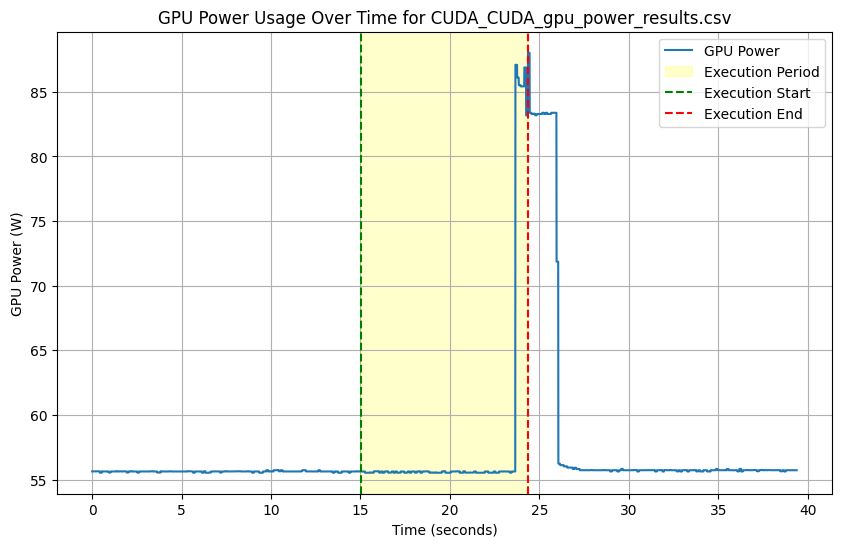

Start time: 15.001 -- End time: 24.378
Code execution duration: 9.38 seconds
Total GPU energy consumption for CUDA_CUDA_gpu_power_results.csv:
  0.000151 kWh
  0.1507 Wh
  542.51 J
Average GPU power: 57.90 W
Total Energy During Exe Runtime:   542.51 J
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!


In [11]:
execute_result, exe_output_source, total_energy_joules, ave_power, duration = lassi.code_manager.execute_code(
    execute_file,
    exe_input_parameters,
    power_measure,
    source_language,
    target_language,
    build_script,
    wait=0
)

Measure system idle power...
Duration for idle time measurement: 21.87
GPU power data has been written to idle__gpu_power_results.csv


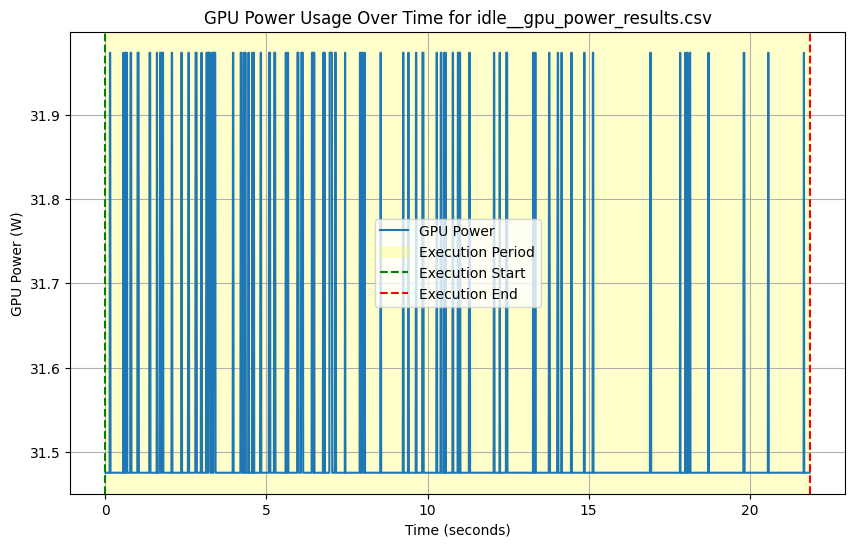

Start time: 0 -- End time: 21.867
Code execution duration: 21.87 seconds
Total GPU energy consumption for idle__gpu_power_results.csv:
  0.000191 kWh
  0.1915 Wh
  689.38 J
Average GPU power: 31.52 W
Total Energy During Exe Runtime:   689.38 J
----------------------------------------------------------------------------------------------------------------------------------------

Actual measured values during runtime for lid-driven-cavity-cuda_main.cu
Average GPU power: 94.84 W
Total Energy During Exe Runtime: 2070.47 J


In [8]:
# Measure system idle power
print("Measure system idle power...")
idle_energy_joules, idle_ave_power = lassi.get_power.idlepower(duration)
actual_energy = total_energy_joules - idle_energy_joules
actual_ave_power = ave_power - idle_ave_power
print(color.BOLD + color.BLUE + "\nActual measured values during runtime for " + color.END + str(code_filename))
print("Average GPU power: " + color.BOLD + f"{actual_ave_power:.2f} W" + color.END)
print("Total Energy During Exe Runtime: " + color.BOLD + f"{actual_energy:.2f} J" + color.END)